# Bài thực hành 1 — KNN và đặc trưng màu

MSSV: 24521185  
Họ và tên: Nguyễn Anh Nguyên

In [1]:
from google.colab import drive
drive.mount('/content/drive')

In [2]:
import os
import cv2
import numpy as np
from PIL import Image

import matplotlib.pyplot as plt
from itertools import product
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score

## Đọc dữ liệu

In [3]:
def load_images_from_folder(folder):
    images, labels, paths = [], [], []
    class_names = sorted(name for name in os.listdir(folder) if os.path.isdir(os.path.join(folder, name)))
    for label, class_name in enumerate(class_names):
        class_folder = os.path.join(folder, class_name)
        for filename in sorted(os.listdir(class_folder)):
            if not filename.lower().endswith('.jpg'):
                continue
            image_path = os.path.join(class_folder, filename)
            image = cv2.imread(image_path)
            if image is None:
                image = cv2.cvtColor(np.array(Image.open(image_path).convert('RGB')), cv2.COLOR_RGB2BGR)
            images.append(image)
            labels.append(label)
            paths.append(image_path)
    return images, np.array(labels), paths, class_names

dataset_folder = '/content/drive/MyDrive/CS231/Dataset/HoaVietNam2027'
train_folder = os.path.join(dataset_folder, 'train')
test_folder = os.path.join(dataset_folder, 'test')
train_images, y_train, _, class_names = load_images_from_folder(train_folder)
test_images, y_test, test_paths, test_class_names = load_images_from_folder(test_folder)
assert class_names == test_class_names
print('Các lớp:', class_names)
print('Train:', len(train_images), '| Test:', len(test_images))

Các lớp: ['Cuc', 'Dao', 'Ga', 'Hong', 'Lan', 'Mai', 'Sen', 'Tho']
Train: 285 | Test: 92


## Yêu cầu 1 — KNN với histogram RGB 256 bin/kênh

In [4]:
def compute_histogram_rgb(image):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    histograms = []
    for channel in range(3):
        hist = cv2.calcHist([image], [channel], None, [256], [0, 256])
        histograms.extend(cv2.normalize(hist, hist).flatten())
    return np.array(histograms)

X_train_rgb = np.array([compute_histogram_rgb(image) for image in train_images])
X_test_rgb = np.array([compute_histogram_rgb(image) for image in test_images])
print('RGB:', X_train_rgb.shape, X_test_rgb.shape)

RGB: (285, 768) (92, 768)


In [5]:
scores = []
for k, weights, metric in product(range(1, 11), ['uniform', 'distance'],
                                  ['braycurtis', 'canberra', 'correlation', 'cosine', 'euclidean', 'minkowski']):
    params = {'n_neighbors': k, 'weights': weights, 'metric': metric}
    model = KNeighborsClassifier(**params).fit(X_train_rgb, y_train)
    accuracy = accuracy_score(y_test, model.predict(X_test_rgb))
    scores.append((accuracy, params))

best_accuracy, best_params = max(scores, key=lambda item: item[0])
print('Tham số tốt nhất:', best_params)
print(f'Accuracy RGB: {best_accuracy:.4f} ({round(best_accuracy * len(y_test))}/{len(y_test)})')

Tham số tốt nhất: {'n_neighbors': 9, 'weights': 'distance', 'metric': 'canberra'}
Accuracy RGB: 0.5761 (53/92)


## Yêu cầu 2 — So sánh các đặc trưng màu

Giữ nguyên tham số KNN từ yêu cầu 1. Moment màu gồm mean, standard deviation và skewness trên RGB; màu chủ đạo gồm ba tâm cụm K-means, theo cách biểu diễn trong bài mẫu.


In [6]:
def compute_histogram_hsv(image, bins):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([image], [0, 1, 2], None, [bins, bins, bins],
                        [0, 180, 0, 256, 0, 256])
    return cv2.normalize(hist, hist).flatten()

def compute_moment_feature(image):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB).astype(np.float32)
    mean = np.mean(image, axis=(0, 1))
    std = np.std(image, axis=(0, 1))
    skewness = np.mean(((image - mean) / (std + 1e-6)) ** 3, axis=(0, 1))
    return np.concatenate([mean, std, skewness])

def compute_dominant_color_feature(image):
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    pixels = image.reshape(-1, 3)
    kmeans = KMeans(n_clusters=3, n_init=10, random_state=42).fit(pixels)
    return kmeans.cluster_centers_.flatten()

In [7]:
features = {
    'Histogram RGB 256×3': (X_train_rgb, X_test_rgb),
    'Histogram HSV 8×8×8': (
        np.array([compute_histogram_hsv(image, 8) for image in train_images]),
        np.array([compute_histogram_hsv(image, 8) for image in test_images])),
    'Moment màu': (
        np.array([compute_moment_feature(image) for image in train_images]),
        np.array([compute_moment_feature(image) for image in test_images])),
    'Màu chủ đạo': (
        np.array([compute_dominant_color_feature(image) for image in train_images]),
        np.array([compute_dominant_color_feature(image) for image in test_images])),
}
accuracies = {}
for name, (X_train, X_test) in features.items():
    model = KNeighborsClassifier(**best_params).fit(X_train, y_train)
    predicted = model.predict(X_test)
    accuracies[name] = accuracy_score(y_test, predicted)
    print(f'{name:<25} {np.sum(predicted == y_test):>2}/{len(y_test)}  Accuracy = {accuracies[name]:.4f}')

Histogram RGB 256×3       53/92  Accuracy = 0.5761
Histogram HSV 8×8×8       62/92  Accuracy = 0.6739
Moment màu                39/92  Accuracy = 0.4239
Màu chủ đạo               41/92  Accuracy = 0.4457


## Yêu cầu 3 — So sánh RGB và HSV 16×16×16 trên tập test

A — RGB: 53/92; Accuracy = 0.5761
B — HSV 16×16×16: 56/92; Accuracy = 0.6087

A sai, B đúng: 16 ảnh
0037.jpg | thực tế: Dao | A: Ga | B: Dao
0036.jpg | thực tế: Hong | A: Sen | B: Hong
0042.jpg | thực tế: Hong | A: Ga | B: Hong
0045.jpg | thực tế: Hong | A: Ga | B: Hong
0049.jpg | thực tế: Hong | A: Ga | B: Hong
0042.jpg | thực tế: Lan | A: Cuc | B: Lan
0031.jpg | thực tế: Mai | A: Cuc | B: Mai
0032.jpg | thực tế: Mai | A: Tho | B: Mai
0033.jpg | thực tế: Mai | A: Tho | B: Mai
0034.jpg | thực tế: Mai | A: Ga | B: Mai
0038.jpg | thực tế: Mai | A: Ga | B: Mai
0040.jpg | thực tế: Mai | A: Tho | B: Mai
0042.jpg | thực tế: Sen | A: Hong | B: Sen
0045.jpg | thực tế: Sen | A: Cuc | B: Sen
0046.jpg | thực tế: Sen | A: Dao | B: Sen
0033.jpg | thực tế: Tho | A: Ga | B: Tho

A đúng, B sai: 13 ảnh
0047.jpg | thực tế: Cuc | A: Cuc | B: Tho
0049.jpg | thực tế: Cuc | A: Cuc | B: Mai
0039.jpg | thực tế: Dao | A: Dao | B: Hong
0041.jpg | thực tế: Ga | A: Ga | B: Dao
0043.jpg | thực tế: Ga | A: Ga | B: 

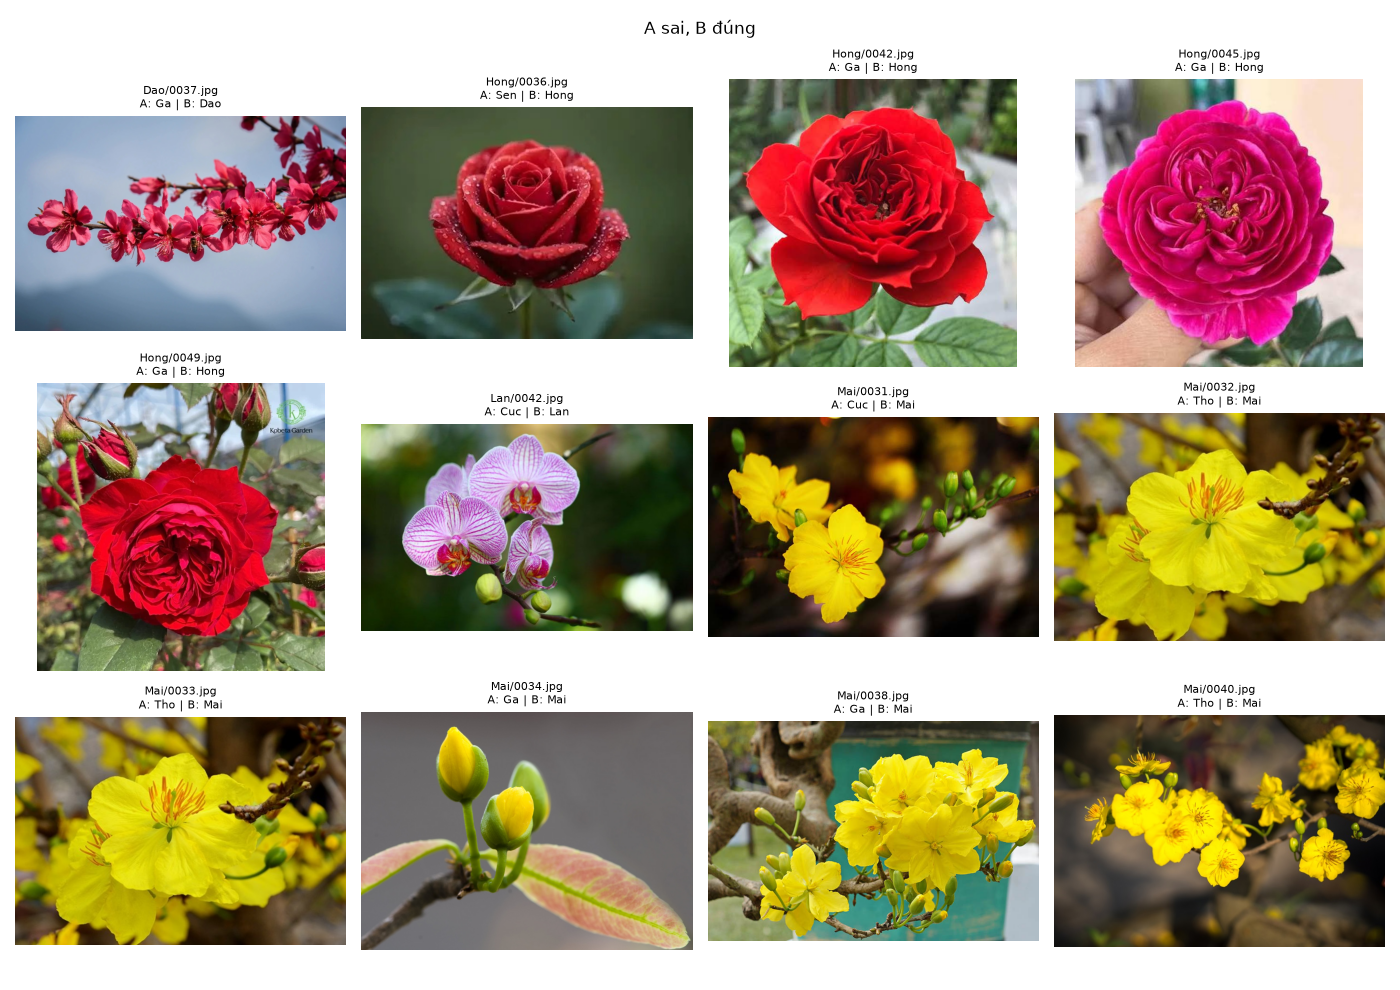

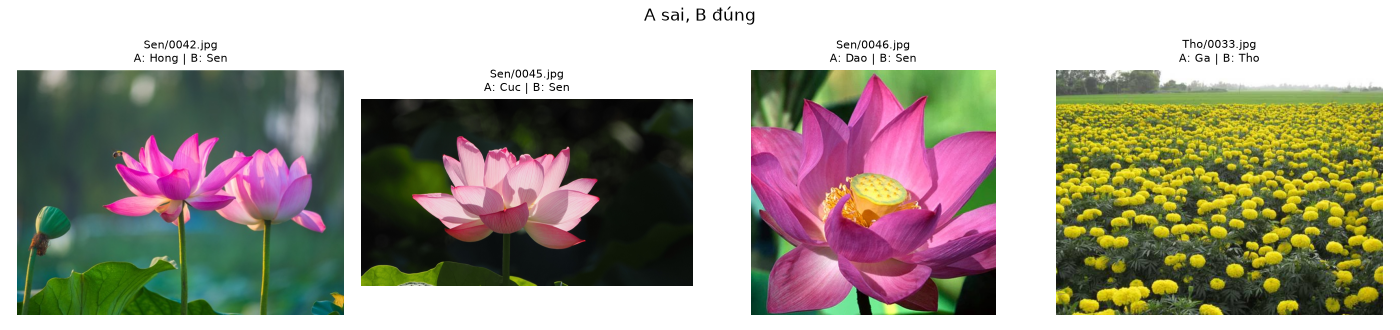

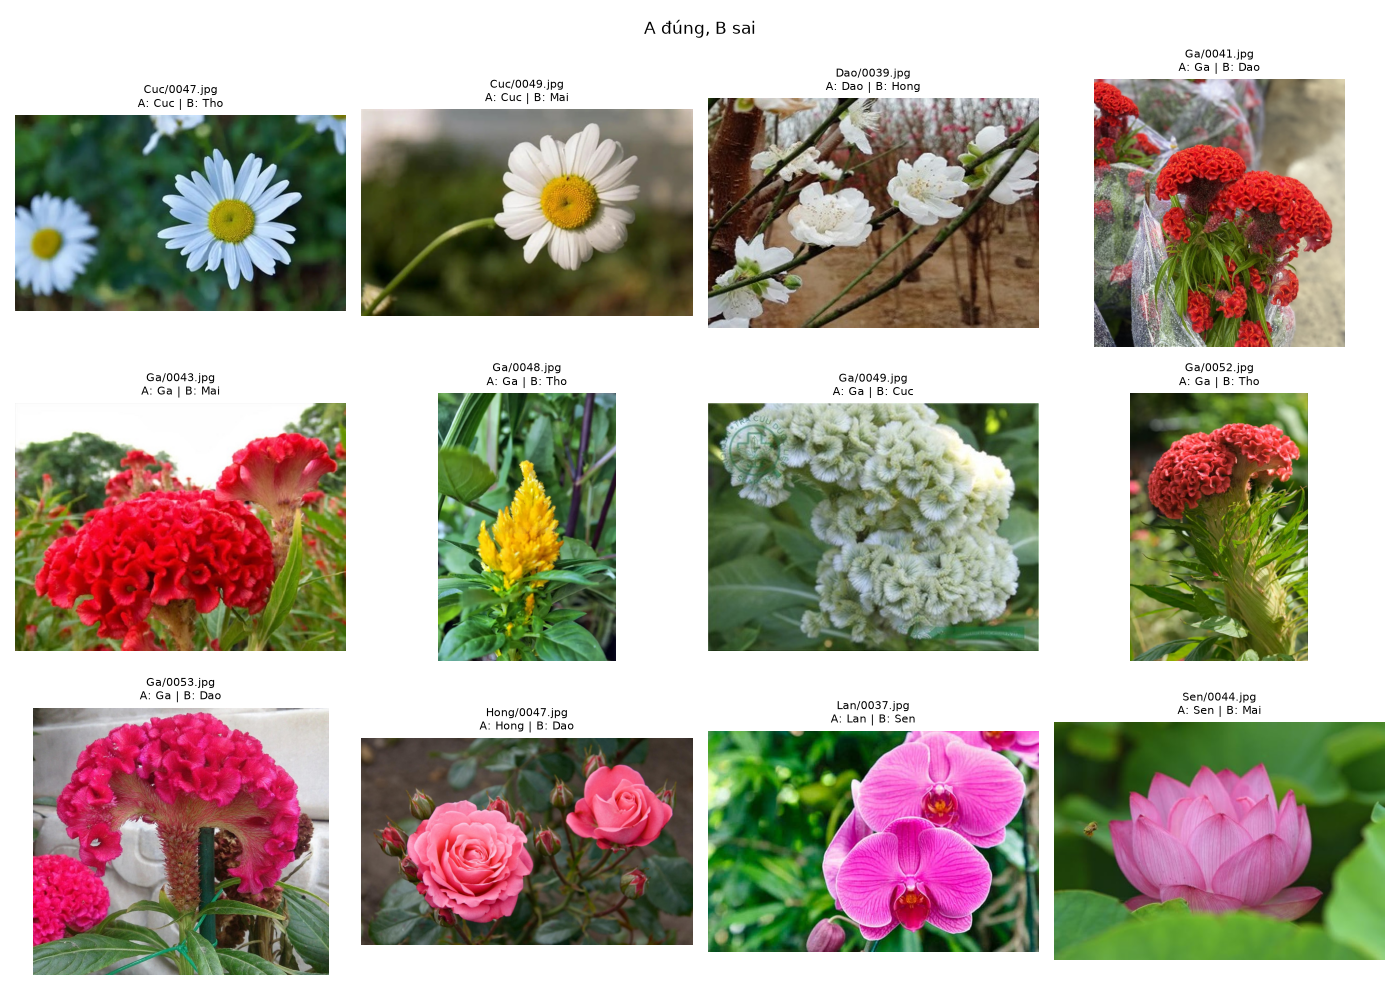

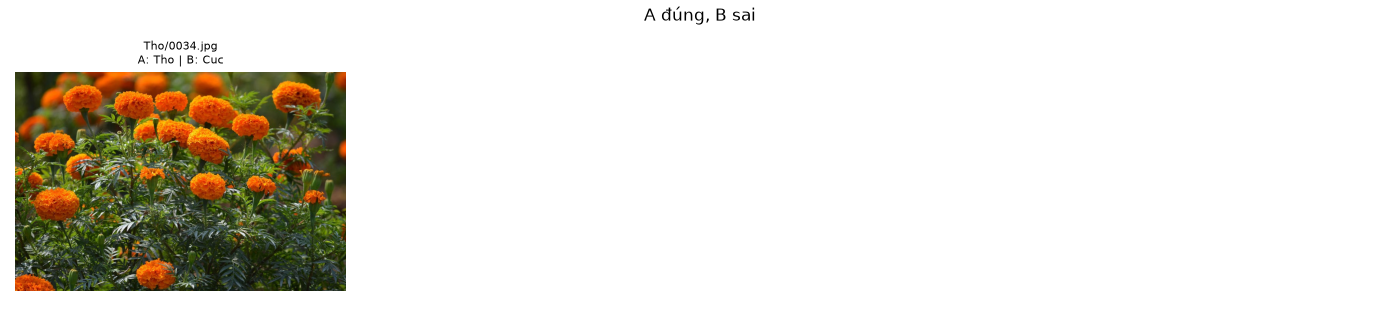

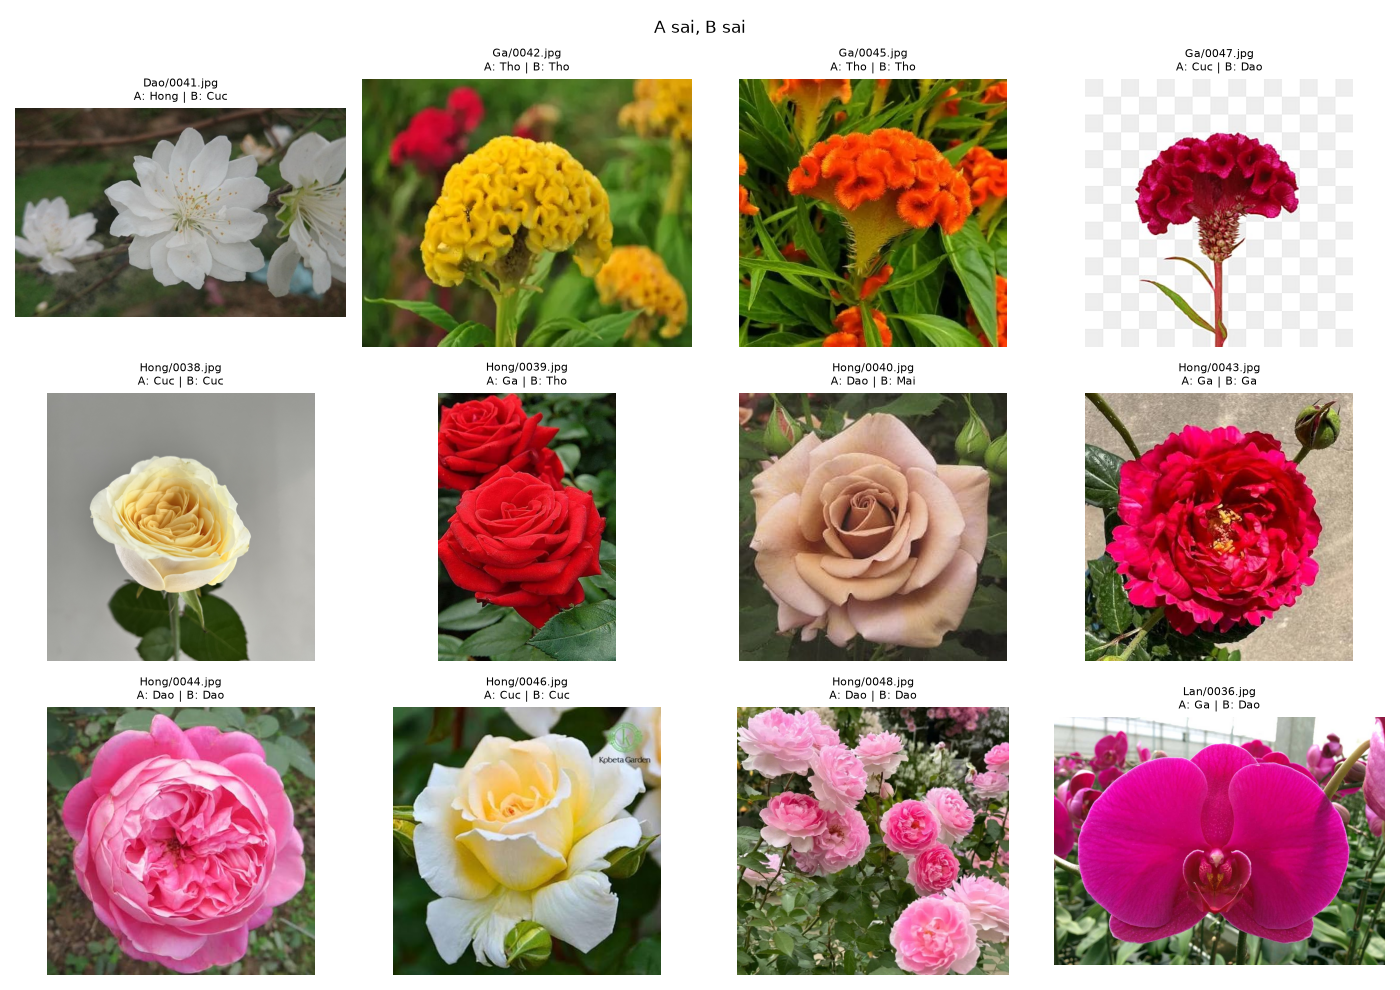

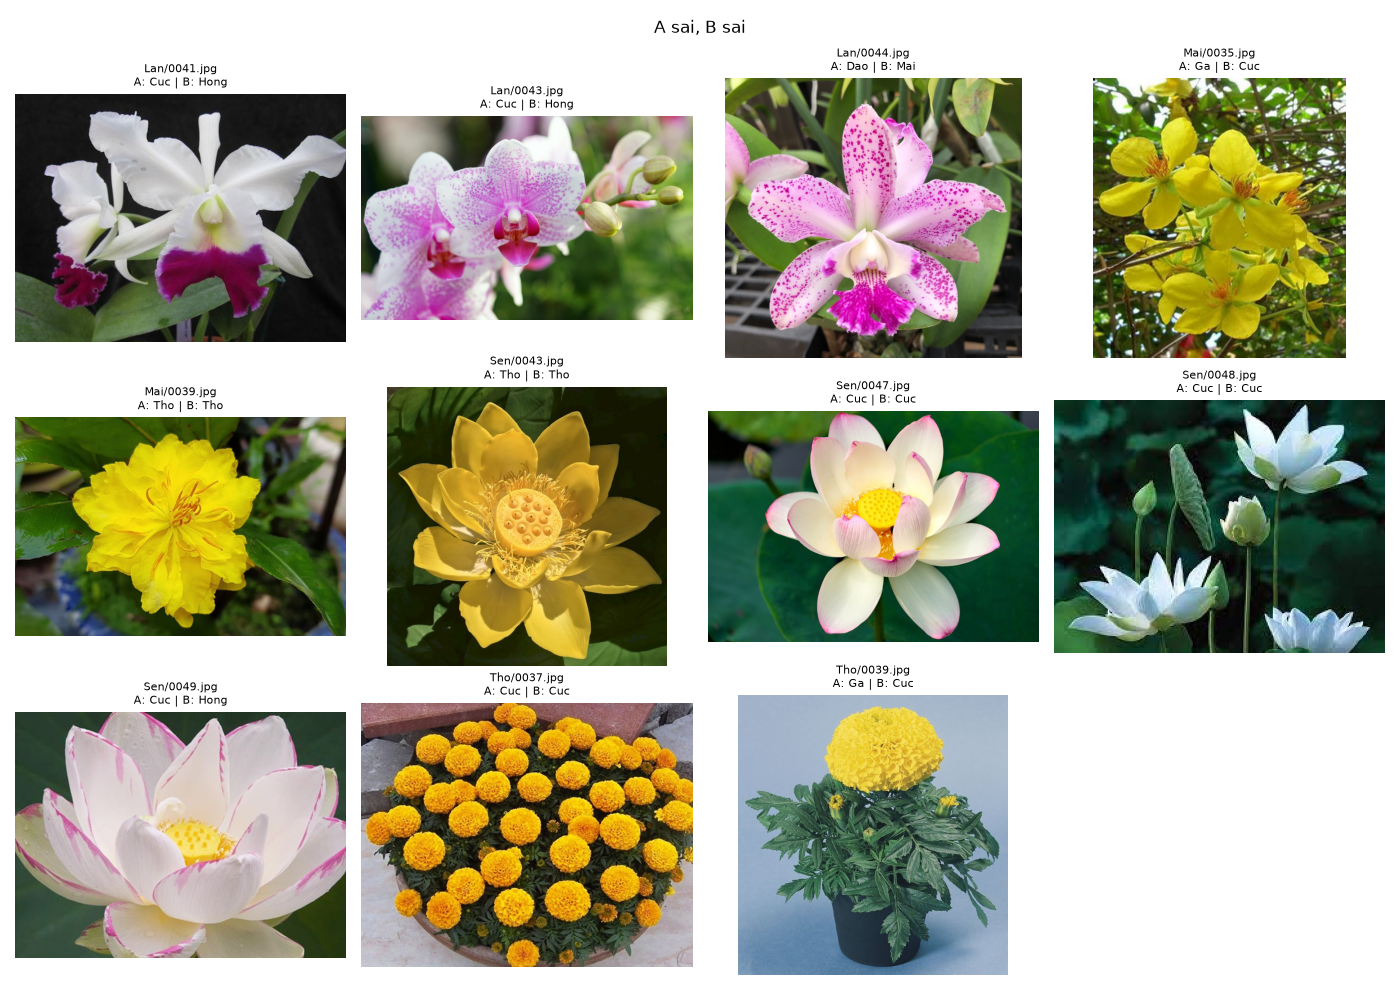

In [8]:
X_train_hsv16 = np.array([compute_histogram_hsv(image, 16) for image in train_images])
X_test_hsv16 = np.array([compute_histogram_hsv(image, 16) for image in test_images])
y_pred_rgb = KNeighborsClassifier(**best_params).fit(X_train_rgb, y_train).predict(X_test_rgb)
y_pred_hsv16 = KNeighborsClassifier(**best_params).fit(X_train_hsv16, y_train).predict(X_test_hsv16)
accuracies['Histogram HSV 16×16×16'] = accuracy_score(y_test, y_pred_hsv16)
print(f'A — RGB: {np.sum(y_pred_rgb == y_test)}/{len(y_test)}; Accuracy = {accuracy_score(y_test, y_pred_rgb):.4f}')
print(f'B — HSV 16×16×16: {np.sum(y_pred_hsv16 == y_test)}/{len(y_test)}; Accuracy = {accuracies["Histogram HSV 16×16×16"]:.4f}')

def show_images(indices, title):
    print(f'\n{title}: {len(indices)} ảnh')
    for index in indices:
        print(f'{os.path.basename(test_paths[index])} | thực tế: {class_names[y_test[index]]} | A: {class_names[y_pred_rgb[index]]} | B: {class_names[y_pred_hsv16[index]]}')
    for start in range(0, len(indices), 12):
        subset = indices[start:start + 12]
        fig, axes = plt.subplots((len(subset) + 3) // 4, 4, figsize=(14, 3.3 * ((len(subset) + 3) // 4)))
        axes = np.array(axes).ravel()
        for ax, index in zip(axes, subset):
            ax.imshow(cv2.cvtColor(test_images[index], cv2.COLOR_BGR2RGB))
            ax.set_title(f'{class_names[y_test[index]]}/{os.path.basename(test_paths[index])}\nA: {class_names[y_pred_rgb[index]]} | B: {class_names[y_pred_hsv16[index]]}', fontsize=8)
            ax.axis('off')
        for ax in axes[len(subset):]:
            ax.axis('off')
        fig.suptitle(title)
        fig.tight_layout()
        plt.show()

show_images(np.where((y_pred_rgb != y_test) & (y_pred_hsv16 == y_test))[0], 'A sai, B đúng')
show_images(np.where((y_pred_rgb == y_test) & (y_pred_hsv16 != y_test))[0], 'A đúng, B sai')
show_images(np.where((y_pred_rgb != y_test) & (y_pred_hsv16 != y_test))[0], 'A sai, B sai')
print('\nĐặc trưng X có Accuracy cao nhất:', max(accuracies, key=accuracies.get))

## Nhận xét

Với 120 tổ hợp tham số đã thử, KNN trên histogram RGB đạt 53/92 ảnh đúng (Accuracy 0,5761) khi `n_neighbors=9`, `weights='distance'`, `metric='canberra'`. Giữ các tham số này, histogram HSV 8×8×8 đạt kết quả cao nhất: 62/92 ảnh đúng (0,6739), nên được chọn làm đặc trưng X cho bài 2. Khi so sánh A (RGB) và B (HSV 16×16×16), B sửa đúng 16 ảnh A dự đoán sai; A đúng ở 13 ảnh B dự đoán sai; cả hai cùng sai ở 23 ảnh.